# Notebook 05: One real measurement with SWSPy

**Goal (about 1.5 hours):** run the full research-pipeline measurement on one real earthquake, reproduce to the digit the row Michael reported for it, and then see what changes when STAR's swapped horizontal components are put the right way round.

The library is SWSPy (Hudson, Asplet & Walker, 2023, *Seismica*; code at [github.com/TomSHudson/swspy](https://github.com/TomSHudson/swspy), MIT licence). The repo carries a local copy with small modifications made for the Axial Seamount and Rainier projects. The wrapper you call is `rainier_sws.measure.measure_event`; open it side by side with this notebook, it is about 80 lines and mirrors `process_event` in the research repo's `run_sws_generic.py`.

In [1]:
# --- setup: make the repo importable and keep figures inline ---
import sys, warnings
from pathlib import Path
REPO = Path.cwd().parent if (Path.cwd() / "../rainier_sws").exists() else Path.cwd()
sys.path.insert(0, str(REPO))
warnings.filterwarnings("ignore")
%matplotlib inline
import numpy as np, pandas as pd, matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
from rainier_sws import paths, data, measure, quality, stats
print("repo:", REPO)

repo: /Users/mhemmett/Seismology/rainier-sws-tutorials


## 1. The target

Event 61504668 at STAR is the example in Michael's figure 3. His pipeline reported:

In [2]:
ref = pd.read_csv(paths.station_results_csv("STAR"))
target = ref[ref.evid == 61504668].iloc[0]
target[["stage", "back_azimuth", "rectilinearity", "incidence_angle_jurkevics", "incidence_angle", "snr_horizontal",
        "filter_band", "phi", "dt", "phi_error", "dt_error", "quality", "dominant_period", "pct_anisotropy"]]

stage                                 ok
back_azimuth                   89.217446
rectilinearity                  0.834067
incidence_angle_jurkevics      45.687378
incidence_angle                29.026402
snr_horizontal                  8.504563
filter_band                  (5.0, 10.0)
phi                           -88.782554
dt                                  0.02
phi_error                            4.0
dt_error                            0.01
quality                              1.0
dominant_period                 0.107413
pct_anisotropy                  1.056812
Name: 33, dtype: object

Two incidence angles are listed. `incidence_angle_jurkevics` (45.7 deg) is estimated from the P-wave particle motion in the data; `incidence_angle` (29.0 deg) is from 3-D ray tracing through a velocity model and is the one the pipeline used. The ray tracer is not included in this repo, so **we pass the stored ray-traced angle in**. Notice already that the two estimates disagree by 17 degrees, and that the pipeline's 45-degree gate would have *rejected* this event on the Jurkevics angle. Hold on to that.

## 2. Run the measurement

In [3]:
cat = data.load_station_catalog("STAR")
row = cat[cat.evid == 61504668].iloc[0]
# Michael's results were computed before STAR's swapped horizontals were found (notebook 02), so to
# reproduce them we need the components as archived. Section 4 redoes the measurement corrected.
ev_archived = data.get_event_stream("STAR", row, allow_download=False, correct_orientation=False)
lat, lon, _ = data.station_coords("STAR")

m = measure.measure_event(row, ev_archived, "STAR", lat, lon, incidence_angle=target.incidence_angle)
mine = pd.Series(m.as_row())
mine[["stage", "back_azimuth", "rectilinearity", "incidence_angle_jurkevics", "snr_horizontal", "filter_band",
      "phi", "dt", "phi_error", "dt_error", "quality", "dominant_period"]]

stage                                 ok
back_azimuth                   89.217446
rectilinearity                  0.834067
incidence_angle_jurkevics      45.687378
snr_horizontal                  8.504563
filter_band                  (5.0, 10.0)
phi                           -88.782554
dt                                  0.02
phi_error                            4.0
dt_error                            0.01
quality                              1.0
dominant_period                 0.107413
dtype: object

In [4]:
compare = pd.DataFrame({"Michael": target, "this notebook": mine}).loc[
    ["back_azimuth", "rectilinearity", "snr_horizontal", "filter_band", "phi", "dt", "phi_error", "dt_error", "quality", "dominant_period"]]
compare["match"] = [np.isclose(float(a), float(b), atol=1e-6) if isinstance(a, (int, float, np.floating)) else a == b
                    for a, b in zip(compare.Michael, compare["this notebook"])]
compare

,Michael,this notebook,match
back_azimuth,89.217446,89.217446,True
rectilinearity,0.834067,0.834067,True
snr_horizontal,8.504563,8.504563,True
filter_band,"(5.0, 10.0)","(5.0, 10.0)",True
phi,-88.782554,-88.782554,True
dt,0.02,0.02,True
phi_error,4.0,4.0,True
dt_error,0.01,0.01,True
quality,1.0,1.0,True
dominant_period,0.107413,0.107413,True


If every row says `True`, you have reproduced a published-quality measurement from raw data. Write the date, your package versions (notebook 00) and this table in your lab notebook: that is your first replicability record.

This event reproduces in every number, but not every event does. In this environment about one STAR event in ten comes out with a different Q_w from Michael's run while everything else matches (exercise 1), and at least one of those (62138152) lands on the other side of the grade-3 cut. So even the archived grade-3 count of 121 depends on the computing environment by an event or so. The cause is the ill-conditioning described in the README: Q_w can tip on floating-point details.

If something does not match, the first suspects are: a different numpy/scipy version changing a floating-point tie-break, a different `filter_band` chosen because the SNR of two bands was nearly equal, or a different incidence angle passed in. Chase it down before continuing; it is the most instructive bug you will meet.

## 3. What the number means

phi is reported as degrees from north in (-90, 90]. -88.8 is the same axis as 91.2: an east-west fast direction. dt is 0.02 s, two samples at 100 Hz, which is tiny; the dominant period is 0.107 s so dt is well under the half-period cycle-skip limit. Q_w is 1.0: the eigenvalue and cross-correlation methods agree perfectly. phi_error 4 degrees and dt_error 0.01 s are the formal errors from the misfit surface.

In [5]:
print(f"phi folded to [0,180): {measure.phi_0_180(m.phi):.1f} deg;  back azimuth {m.back_azimuth:.1f} deg;"
      f"  angle between fast axis and back azimuth: {stats.axial_diff(m.phi, m.back_azimuth):.1f} deg")

phi folded to [0,180): 91.2 deg;  back azimuth 89.2 deg;  angle between fast axis and back azimuth: 2.0 deg


Pause on that last number. The fast axis is within 2 degrees of the back azimuth. A measurement with phi parallel (or perpendicular) to the initial polarization is the geometry of a **null** (notebook 04, section 6): little or no splitting is visible, and the grid search can still report a confident-looking answer. One event cannot settle whether this is a null or a real east-west fast axis; notebook 07 screens for it across the whole catalog. (Hold on to it for section 4, too.)

## 4. The components were the wrong way round

Everything above used STAR's horizontals as they are labelled in the archive, which is how the research results were computed. But at STAR the sensor labelled `EHN` points east and the one labelled `EHE` points north (notebook 02). Swapping N and E mirrors every direction across the north-east diagonal, and the measurement rotates the horizontals into the ray's frame using the back azimuth, so a fast direction measured on swapped data is not simply the true one relabelled. Re-measure with the components corrected, everything else (incidence angle, parameters) the same:

In [6]:
ev = data.get_event_stream("STAR", row, allow_download=False)        # corrected: true Z, N, E
m_fixed = measure.measure_event(row, ev, "STAR", lat, lon, incidence_angle=target.incidence_angle)
cols = ["stage", "filter_band", "snr_horizontal", "phi", "dt", "phi_error", "dt_error", "quality", "dominant_period"]
both = pd.DataFrame({"as archived (Michael)": pd.Series(m.as_row())[cols], "corrected": pd.Series(m_fixed.as_row())[cols]})
both.loc["phi folded to [0, 180)"] = [measure.phi_0_180(m.phi), measure.phi_0_180(m_fixed.phi)]
both.loc["fast axis vs back azimuth (deg)"] = [stats.axial_diff(m.phi, m.back_azimuth), stats.axial_diff(m_fixed.phi, m_fixed.back_azimuth)]
both

,as archived (Michael),corrected
stage,ok,ok
filter_band,"(5.0, 10.0)","(5.0, 10.0)"
snr_horizontal,8.504563,8.504563
phi,-88.782554,25.217446
dt,0.02,0.08
phi_error,4.0,4.0
dt_error,0.01,0.01
quality,1.0,0.0
dominant_period,0.107413,0.107413
"phi folded to [0, 180)",91.217446,25.217446


Same filter band, same SNR (the horizontal SNR does not depend on which way the horizontals point), same dominant period, and a completely different answer: phi 25 degrees (north-north-east) instead of 91, dt 0.08 s instead of 0.02, and Q_w 0 instead of 1. Q_w compares the eigenvalue and cross-correlation methods, and 0 means they disagree. And 0.08 s is more than half the dominant period (0.054 s), the cycle-skip limit from notebook 03.

So, corrected, this event fails grade 3 twice over (Q_w below 0.5, dt above half a period), and the clean near-null of section 3, fast axis 2 degrees from the back azimuth, was a product of the swapped components. The same is true across the station: re-measured with corrected components, STAR's grade-3 set is 78 events instead of 121, with only 12 in common (the note at the top of notebook 06 has the details). The rest of this notebook uses the corrected data.

## 5. Look at the diagnostic plot

SWSPy can draw the standard splitting diagnostic: the filtered traces, the particle motion before and after correction, and the misfit surface with its error contour. This is the corrected measurement. Compare it with your synthetic surfaces from notebook 04. (The local copy's `plot()` is a poster-sized variant; `plot_orig()` is the standard figure.)

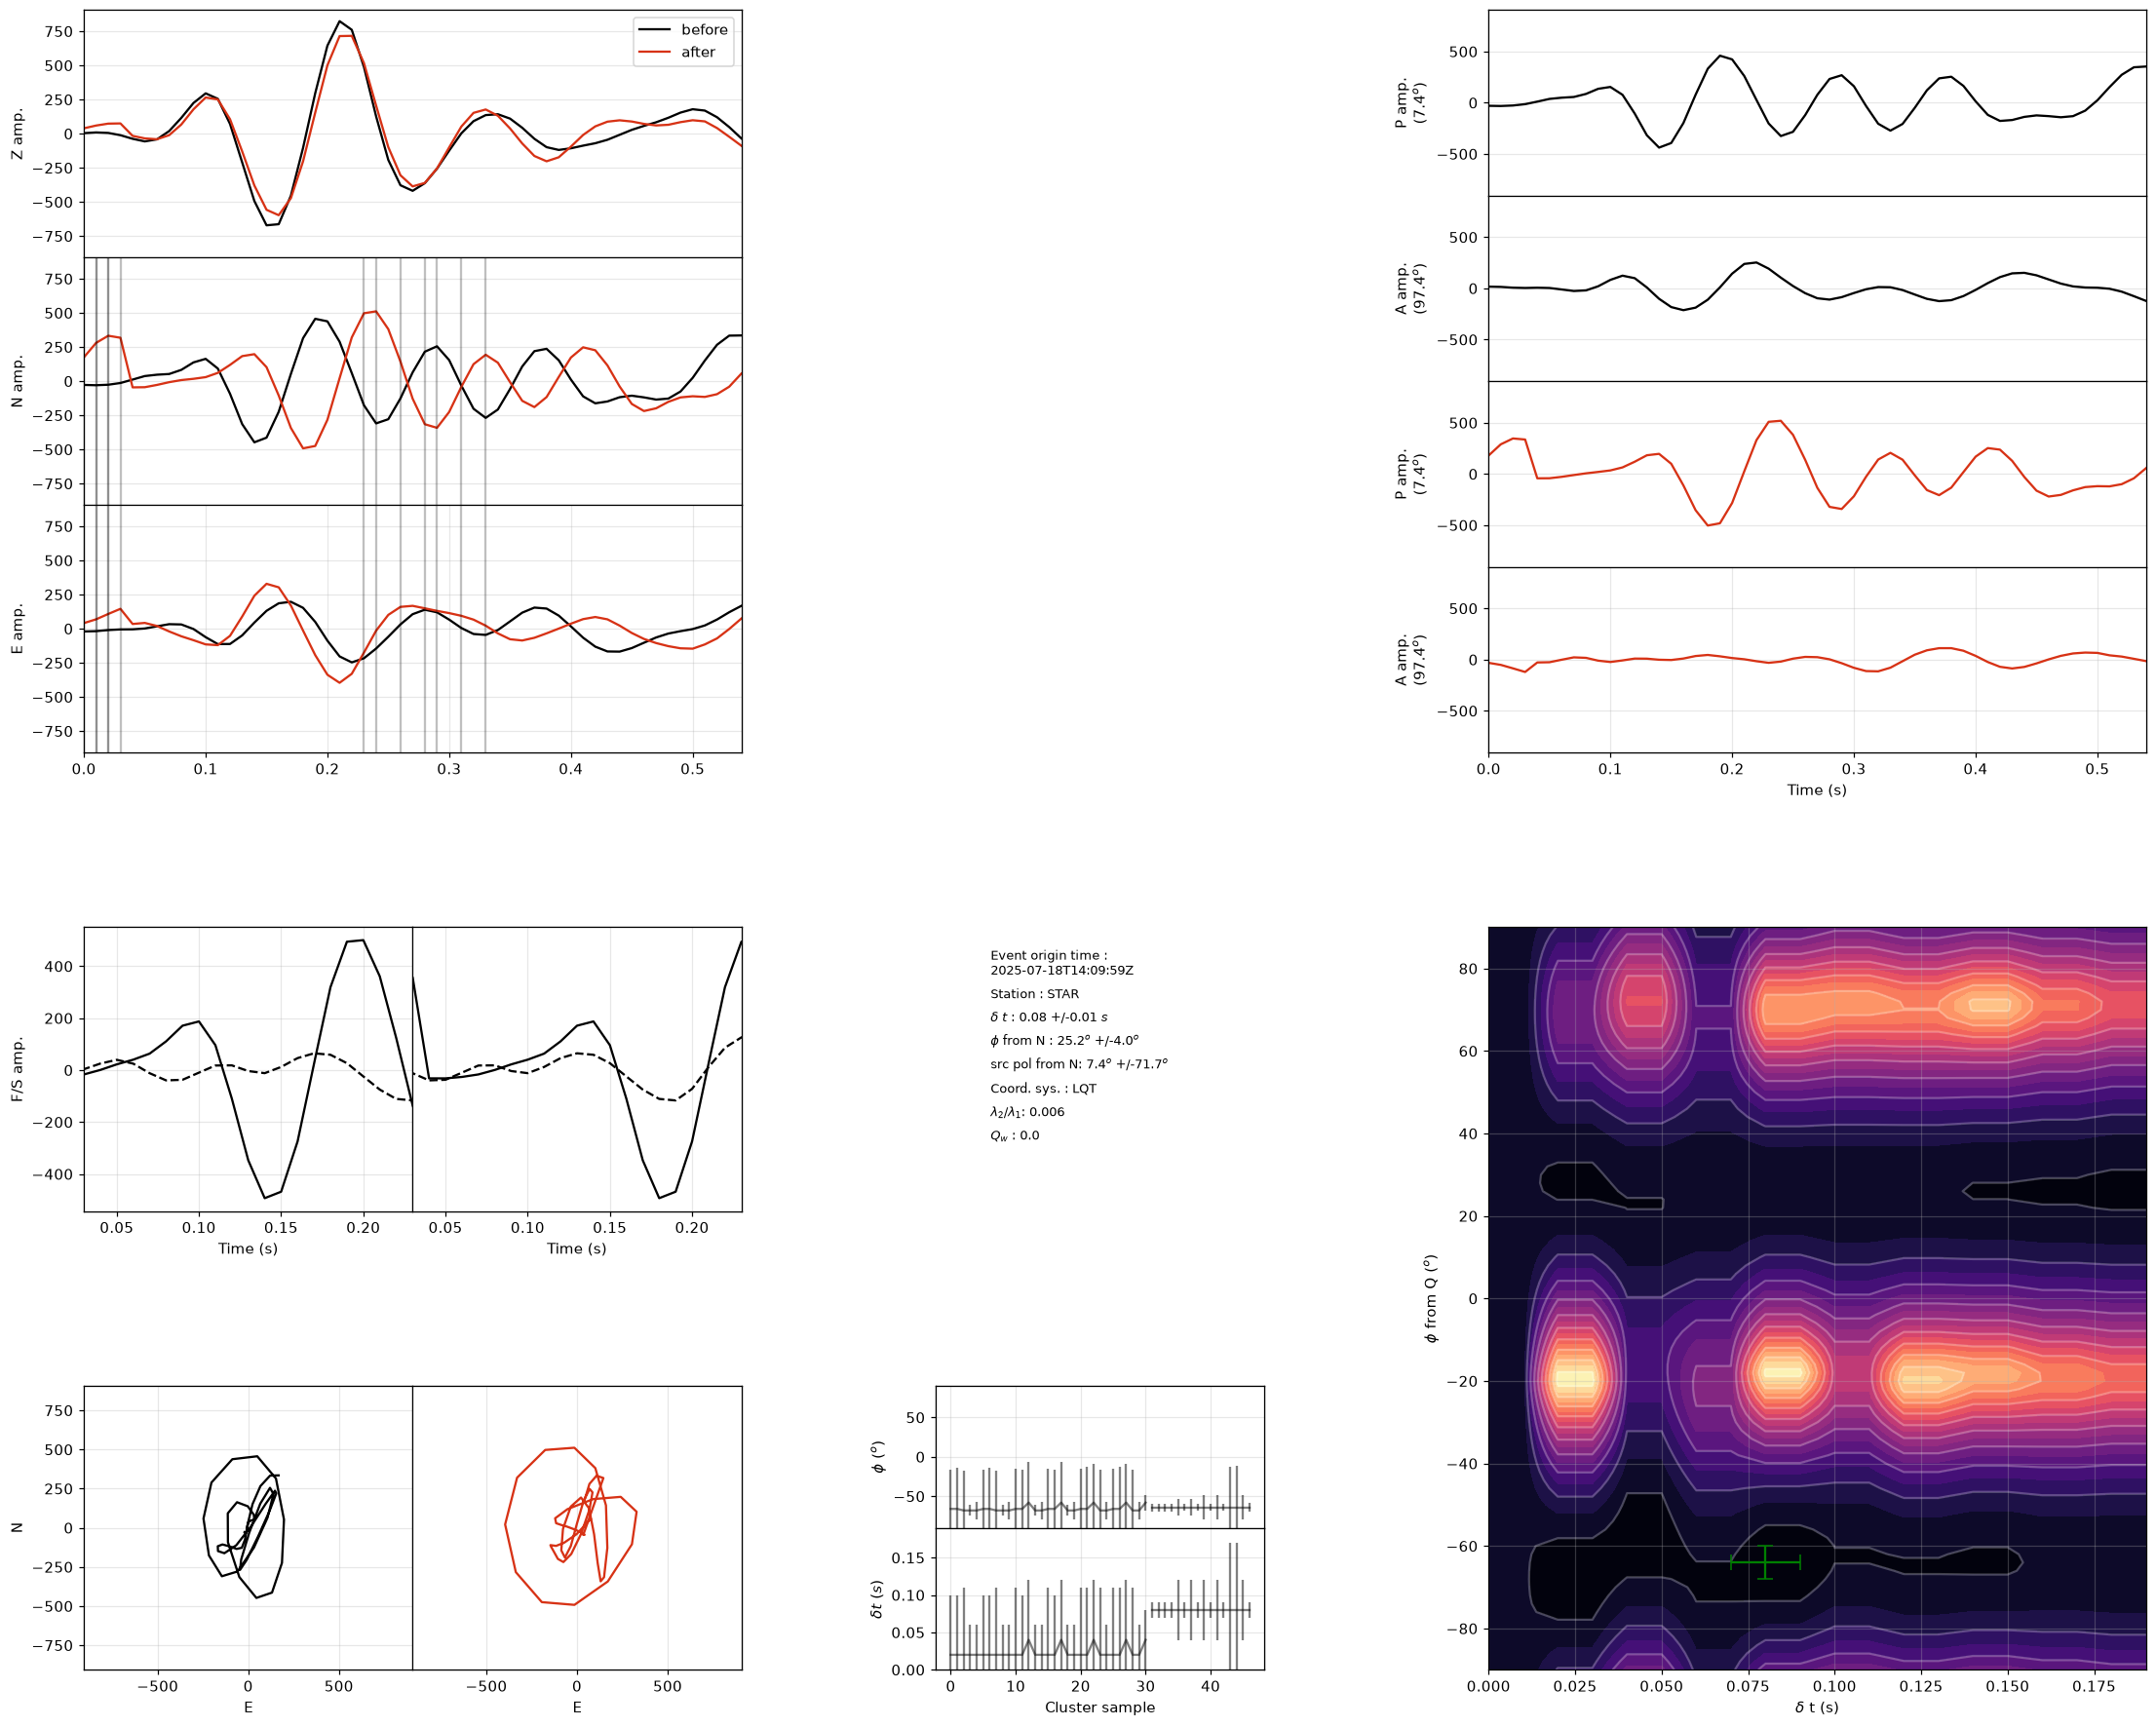

In [7]:
so = m_fixed.splitting_object
so.plot_orig(suppress_direct_plotting=False)

## 6. The same event with a different incidence angle

The incidence angle enters twice: as a gate (reject if above 45 degrees) and as the inclination of the LQT rotation that isolates the S wave. Rerun with the data-derived Jurkevics angle and with a few values in between. On the corrected data this event is not stable: phi stays between 21 and 31 degrees from 25 to 44 degrees of incidence, but dt jumps between 0.08 and 0.02 s and Q_w between 0 and 0.9, and at 15 degrees phi swings to about 100. The *gate* behaviour is not stable either.

In [8]:
rows = []
for inc in [15, 25, target.incidence_angle, 35, 44, target.incidence_angle_jurkevics]:
    mm = measure.measure_event(row, ev, "STAR", lat, lon, incidence_angle=inc)
    rows.append({"incidence_used": round(inc, 1), "stage": mm.stage, "phi": mm.phi, "dt": mm.dt,
                 "phi_error": mm.phi_error, "dt_error": mm.dt_error, "Q_w": mm.quality})
pd.DataFrame(rows)

,incidence_used,stage,phi,dt,phi_error,dt_error,Q_w
0,15.0,ok,-78.782554,0.02,4.0,0.01,0.000000
1,25.0,ok,21.217446,0.08,3.0,0.01,0.000000
2,29.0,ok,25.217446,0.08,4.0,0.01,0.000000
3,35.0,ok,27.217446,0.02,7.0,0.01,0.905719
4,44.0,ok,31.217446,0.02,8.0,0.01,0.905719
5,45.7,fail_incidence,NaN,NaN,NaN,NaN,NaN


This is the known reason PANH, OBSR, PARA, RER and COPP have (near) zero measurements in the research results: with the ray-traced angles, essentially none of their swarm events fall inside the 45-degree shear-wave window. So the question for those stations is not "is the measurement wrong" but "is the gate right, and how sensitive is everything to the velocity model behind the angle". That is a threshold question, and notebook 07 is about thresholds.

## 7. Exercises

1. Pick five more STAR events from `ref` with `stage == "ok"` and reproduce them (with `correct_orientation=False`, as in section 2). Keep a table of matches. Any mismatches: diagnose.
2. Pick two events with `stage == "fail_snr"` and run them with `gates=quality.PreGates(snr_min=1.0)`. Do you get a measurement? Does it pass grade 3 (`quality.grade3_mask` on a one-row DataFrame)? Would you trust it?
3. Time one measurement (`%%time`). Estimate how long all 900 STAR events take, and how long a 10-value parameter sweep over all events would take. This number decides the design of notebook 07.
4. (Stretch) In `measure_event`, the filter band is chosen before the gates are applied. Would choosing it after change anything? Why might the order matter for replicability?

Next: `06_exploring_the_results.ipynb`.

## 8. Example solutions

One way to do each exercise. Try them yourself first. Each measurement takes a fraction of a second, so these cells run in well under a minute.

### Exercise 1: reproduce five more events

Pick five events at random (fixed `random_state`, so the choice is repeatable) from the rows Michael's pipeline measured, re-measure them on the components *as archived* with the stored ray-traced incidence angle, and compare every number.

In [9]:
cols = ["filter_band", "snr_horizontal", "phi", "dt", "phi_error", "dt_error", "quality", "dominant_period"]
five = ref[(ref.stage == "ok") & (ref.evid != 61504668)].sample(5, random_state=3)
cat_by_evid = cat.set_index("evid")

def remeasure(evid, correct_orientation):
    r = cat_by_evid.loc[evid].copy(); r["evid"] = evid
    st = data.get_event_stream("STAR", r, allow_download=False, correct_orientation=correct_orientation)
    inc = ref.set_index("evid").loc[evid, "incidence_angle"]
    return measure.measure_event(r, st, "STAR", lat, lon, incidence_angle=inc)

table = []
for _, t in five.iterrows():
    mm = remeasure(t.evid, correct_orientation=False)
    mine_row = pd.Series(mm.as_row())
    match = {c: (mine_row[c] == str(t[c])) if c == "filter_band"
             else bool(np.isclose(float(mine_row[c]), float(t[c]), atol=1e-6)) for c in cols}
    table.append({"evid": t.evid, "stage": mm.stage, "phi (Michael)": t.phi, "phi (mine)": mm.phi,
                  "dt (Michael)": t["dt"], "dt (mine)": mm.dt, "Q_w (Michael)": t.quality, "Q_w (mine)": mm.quality,
                  "all 8 numbers match": all(match.values())})
pd.DataFrame(table).round(3)

,evid,stage,phi (Michael),phi (mine),dt (Michael),dt (mine),Q_w (Michael),Q_w (mine),all 8 numbers match
0,62136077,ok,-63.682,-63.682,0.16,0.16,0.033,-0.953,False
1,62141297,ok,-89.184,-89.184,0.02,0.02,1.000,1.000,True
2,62135682,ok,8.877,8.877,0.02,0.02,0.000,0.000,True
3,62135047,ok,-84.605,-84.605,0.08,0.08,1.000,1.000,True
4,62141592,ok,-86.783,-86.783,0.02,0.02,1.000,1.000,True


Four of the five match in every number. The fifth, 62136077, matches in phi, dt, both formal errors, the filter band, the SNR and the dominant period, and differs in **Q_w only**: Michael's run gave 0.033, this one gives -0.953, and it gives -0.953 every time it is run here. So the difference is between the two computing environments, not random.

Diagnosis: Q_w compares the answers of two methods, the eigenvalue grid search and a cross-correlation, and the cross-correlation answer for a marginal event can tip on floating-point details (library versions, CPU). This is the same ill-conditioning the README describes: a perturbation of 1e-9 counts can move Q_w by a similar amount. It is not rare. A wider check of 60 random STAR events gives 6 with Q_w alone different, and in one of them (62138152, Michael 1.0, here -0.86) the difference moves the event across the grade-3 threshold of 0.5. For 62136077 it does not matter (phi_error is 91 degrees, so it fails grade 3 either way), but it means a reproduction table should always include Q_w, and "reproduced to the digit" has to name the environment.

In [10]:
# the same five with the components the right way round
rows_fixed = []
for _, t in five.iterrows():
    mm = remeasure(t.evid, correct_orientation=True)
    one = pd.DataFrame([mm.as_row()])
    rows_fixed.append({"evid": t.evid, "phi archived": round(measure.phi_0_180(t.phi), 1),
                       "phi corrected": round(measure.phi_0_180(mm.phi), 1) if mm.success else np.nan,
                       "dt archived": t["dt"], "dt corrected": mm.dt,
                       "Q_w archived": round(t.quality, 2), "Q_w corrected": round(mm.quality, 2),
                       "grade 3 archived": bool(quality.grade3_mask(five[five.evid == t.evid]).iloc[0]),
                       "grade 3 corrected": bool(quality.grade3_mask(one).iloc[0])})
pd.DataFrame(rows_fixed)

,evid,phi archived,phi corrected,dt archived,dt corrected,Q_w archived,Q_w corrected,grade 3 archived,grade 3 corrected
0,62136077,116.3,94.3,0.16,0.12,0.03,0.40,False,False
1,62141297,90.8,106.8,0.02,0.16,1.00,-0.92,True,False
2,62135682,8.9,72.9,0.02,0.04,0.00,1.00,False,False
3,62135047,95.4,77.4,0.08,0.14,1.00,0.00,True,False
4,62141592,93.2,21.2,0.02,0.04,1.00,0.11,True,False


Corrected, every one of the five moves, by 16 to 72 degrees in phi, and dt changes for all five. Three of the five passed grade 3 on the archived components (all three with phi near 90, the east-west near-null pattern); **none** passes once the components are right. That is the station-wide picture of section 4 in miniature: the east-west cluster was largely the swap.

### Exercise 2: lower the SNR gate

Take two events that stopped at the SNR gate and run them again with the gate lowered from 2 to 1, on the corrected components (the rest of this notebook uses those). Then ask the grade-3 filter about the result: build a one-row DataFrame from `as_row()` and pass it to `quality.grade3_mask`.

In [11]:
low = ref[ref.stage == "fail_snr"].sort_values("snr_horizontal", ascending=False)
print(f"{len(low)} STAR events stopped at the SNR gate; their horizontal SNR ranges "
      f"{low.snr_horizontal.min():.2f} to {low.snr_horizontal.max():.2f}")
two = pd.concat([low.iloc[[0]], low.iloc[[len(low) // 2]]])      # the best of them and a typical one

out = []
for _, t in two.iterrows():
    r = cat_by_evid.loc[t.evid].copy(); r["evid"] = t.evid
    st = data.get_event_stream("STAR", r, allow_download=False)
    for gate in (2.0, 1.0):
        mm = measure.measure_event(r, st, "STAR", lat, lon, incidence_angle=t.incidence_angle,
                                   gates=quality.PreGates(snr_min=gate))
        one = pd.DataFrame([mm.as_row()])
        out.append({"evid": t.evid, "snr_min": gate, "SNR": round(mm.snr_horizontal, 2), "stage": mm.stage,
                    "phi": mm.phi, "dt": mm.dt, "phi_err": mm.phi_error, "dt_err": mm.dt_error,
                    "Q_w": mm.quality, "grade 3": bool(quality.grade3_mask(one).iloc[0])})
pd.DataFrame(out).round(3)

20 STAR events stopped at the SNR gate; their horizontal SNR ranges 1.30 to 1.99


,evid,snr_min,SNR,stage,phi,dt,phi_err,dt_err,Q_w,grade 3
0,62141207,2.0,1.99,fail_snr,NaN,NaN,NaN,NaN,NaN,False
1,62141207,1.0,1.99,ok,85.468,0.08,13.0,0.03,-0.764,False
2,62135297,2.0,1.70,fail_snr,NaN,NaN,NaN,NaN,NaN,False
3,62135297,1.0,1.70,ok,-75.234,0.02,7.0,0.01,0.969,False


Twenty STAR events stopped at the SNR gate, all just below it (SNR 1.30 to 1.99). With the gate at 1, both of these get measured:

- 62141207 (SNR 1.99, as close to the gate as it gets): phi 85, dt 0.08 s, but Q_w -0.76, which in the Wüstefeld scheme points to a **null** rather than a split.
- 62135297 (SNR 1.70): phi -75 (105), dt 0.02 s, phi_error 7, Q_w 0.97. On every quality number except the SNR this looks like a good measurement.

Neither passes grade 3, and it is not because of the measurements: grade 3 has its own SNR cut at 2 (`quality.Grade3.snr_min`), so lowering only the pre-processing gate can never add a grade-3 event. The two thresholds are coupled, which is easy to miss when you sweep one at a time.

Would I trust 62135297? Not on its own. A Q_w near 1 means the two methods agree, not that the answer is right, and at SNR 1.7 the noise is more than half the signal amplitude. Notebook 04 showed that at low SNR the formal error underestimates the actual error. It is a candidate for the synthetic calibration project in notebook 07, not for the rose.

### Exercise 3: how long does a measurement take?

`%%time` prints a number but does not keep it, so time a handful of measurements with `time.perf_counter` instead and use the median.

In [12]:
import time
sample = ref[ref.stage == "ok"].sample(10, random_state=0)
seconds = []
for _, t in sample.iterrows():
    r = cat_by_evid.loc[t.evid].copy(); r["evid"] = t.evid
    st = data.get_event_stream("STAR", r, allow_download=False)
    t0 = time.perf_counter()
    measure.measure_event(r, st, "STAR", lat, lon, incidence_angle=t.incidence_angle)
    seconds.append(time.perf_counter() - t0)
per_event = float(np.median(seconds))
n_events = len(ref)
print(f"one measurement: median {per_event:.2f} s (range {min(seconds):.2f} to {max(seconds):.2f} s over {len(seconds)} events)")
print(f"all {n_events} STAR events: about {per_event * n_events / 60:.1f} min")
print(f"a 10-value sweep of one parameter over all of them: about {10 * per_event * n_events / 60:.0f} min")
print(f"the same sweep at 10 stations of similar size: about {100 * per_event * n_events / 3600:.1f} h")

one measurement: median 0.15 s (range 0.07 to 0.16 s over 10 events)
all 903 STAR events: about 2.2 min
a 10-value sweep of one parameter over all of them: about 22 min
the same sweep at 10 stations of similar size: about 3.7 h


About 0.2 s per event on this machine (the batch re-run of all 901 STAR events earlier in this project took about 2 minutes, which agrees). So:

- one station, one setting: a few minutes;
- a 10-value sweep of one *processing* parameter (windows, pick uncertainty, incidence angle) over one station: about half an hour;
- the same over ten stations: an afternoon.

That is feasible on a laptop, but not inside an interactive notebook, which is why notebook 07 sweeps the grade-3 thresholds on the results table and re-measures only a single event. Sweeping the *grade-3* thresholds (Q_w, errors, SNR) needs no re-measurement at all, because they only filter rows that already exist, so those sweeps run on the results table in milliseconds. Only processing parameters need the pipeline re-run, and those belong in a script that writes a results file, the week-8 deliverable.

### Exercise 4 (stretch): does it matter that the band is chosen before the gates?

Look at what each gate uses. The rectilinearity and incidence gates are computed from the *unfiltered* traces, so they do not depend on the band at all. Only the SNR gate does, and it uses the SNR of the band that was just chosen. A quick check of how decisive that choice is: rank the bands by SNR for the five events of exercise 1 and look at the margin between the best and the second best.

In [13]:
from rainier_sws import sws_functions as swsf

margins = []
for evid in five.evid:
    r = cat_by_evid.loc[evid].copy(); r["evid"] = evid
    st = data.get_event_stream("STAR", r, allow_download=False)
    _, p_time, s_time, _, _ = measure.pick_offsets(st, r)
    band, _, snr, _, snr_by_band = swsf.try_filters(st, p_time, s_time)
    ranked = sorted(((v, k) for k, v in snr_by_band.items() if np.isfinite(v)), reverse=True)
    margins.append({"evid": evid, "best band": band, "best SNR": round(ranked[0][0], 2),
                    "second band": ranked[1][1], "second SNR": round(ranked[1][0], 2),
                    "margin (%)": round(100 * (ranked[0][0] - ranked[1][0]) / ranked[0][0], 1)})
pd.DataFrame(margins)

,evid,best band,best SNR,second band,second SNR,margin (%)
0,62136077,"(3.0, 5.0)",5.48,"(1.0, 5.0)",3.54,35.4
1,62141297,"(3.0, 15.0)",3.67,"(1.0, 8.0)",3.61,1.5
2,62135682,"(10.0, 45.0)",4.44,"(1.0, 5.0)",4.13,7.1
3,62135047,"(2.0, 8.0)",4.19,"(1.0, 5.0)",4.18,0.3
4,62141592,"(5.0, 10.0)",7.16,"(2.0, 8.0)",5.99,16.3


**Would choosing the band after the gates change anything?** Not the outcome. The rectilinearity and incidence gates are computed on the unfiltered traces, so they do not care about the band, and the SNR gate needs a band to compute its SNR. Choosing the band first does have one bookkeeping advantage: every row, including those that fail rectilinearity or incidence, records a band and an SNR, so the funnel can be read the same way for every event.

**Why the order and the choice matter for replicability.** The band is an argmax over 14 noisy SNR values, and the table shows how thin that argmax can be. For two of these five events the best and second-best bands are within 2 percent of each other (62141297: 3.67 versus 3.61; 62135047: 4.19 versus 4.18), and the two bands are very different (3-15 Hz versus 1-8 Hz). A slightly different noise window, pick or software version could pick the other band and give a different measurement. That is why the band is a recorded output (`filter_band`) and part of the reproduction check, and why any change that alters *which* SNRs are compared, or when, can quietly change results that look unrelated.